# B2 - Đối chiếu BM25 tự cài với Pyserini

Notebook này thực hiện B2 của Lab01 trên SciFact và NFCorpus. Tiêu chí đạt là chênh lệch tuyệt đối nDCG@10 giữa BM25 tự cài và Pyserini/Lucene nhỏ hơn `0.01`. Công thức BM25 và nDCG được giữ nguyên; chỉ đồng bộ tokenizer với analyzer thực tế của Lucene index.

## 1. Mục tiêu

So sánh ba cấu hình cho mỗi tập: BM25 tự cài với whitespace tokenizer, BM25 tự cài với Lucene analyzer và Pyserini/Lucene BM25. Mọi cấu hình dùng `title + text`, qrels test, `k1=1.2`, `b=0.75`, top-100 và `ndcg_at_k()` từ Phần A.

## 2. Chuẩn bị

Các cell dưới đây chỉ đọc dữ liệu và Lucene index đã có. Không có lệnh tải dữ liệu hay tạo index. `SimpleSearcher` là thành phần Lucene nền của Pyserini; nó cung cấp chính analyzer đang dùng khi truy vấn.

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv

# Thư mục gốc dự án
PROJECT_ROOT = Path.cwd().parent

# Đọc file .env
load_dotenv(PROJECT_ROOT / ".env")

# Lấy đường dẫn Java
java_home = os.getenv("JAVA_HOME")

if not java_home:
    raise ValueError("Chưa cấu hình JAVA_HOME trong file .env")

# Cấu hình Java cho Pyserini
os.environ["JAVA_HOME"] = java_home
os.environ["PATH"] = str(Path(java_home) / "bin") + os.pathsep + os.environ["PATH"]

print("Đã cấu hình Java thành công")

Đã cấu hình Java thành công


In [2]:
import sys
from pathlib import Path

# Thêm thư mục gốc vào đường dẫn import
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import các module tự cài
from bm25 import ChiMuc
from chi_so import ndcg_at_k

# Đường dẫn dữ liệu
DATA_DIR = PROJECT_ROOT / "phanB" / "du_lieu"

SCIFACT_DIR = DATA_DIR / "scifact"
NFCORPUS_DIR = DATA_DIR / "nfcorpus"

# Đường dẫn Lucene index
SCIFACT_INDEX = DATA_DIR / "pyserini" / "indexes" / "scifact"
NFCORPUS_INDEX = DATA_DIR / "pyserini" / "indexes" / "nfcorpus"

print("Import thành công")

Import thành công


In [3]:
from beir.datasets.data_loader import GenericDataLoader

def load_test_dataset(dataset_name):
    dataset_dir = DATA_DIR / dataset_name

    if not dataset_dir.is_dir():
        raise FileNotFoundError(f"Không tìm thấy dữ liệu: {dataset_name}")

    corpus, queries, qrels = GenericDataLoader(
        data_folder=str(dataset_dir)
    ).load(split="test")

    return corpus, queries, qrels

d:\RAG\tep_kem\.venv\Lib\site-packages\beir\datasets\data_loader.py:8: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


In [4]:
scifact_corpus, scifact_queries, scifact_qrels = load_test_dataset("scifact")

nfcorpus_corpus, nfcorpus_queries, nfcorpus_qrels = load_test_dataset("nfcorpus")

print("SciFact:")
print("Tài liệu:", len(scifact_corpus))
print("Truy vấn:", len(scifact_queries))
print("Qrels:", len(scifact_qrels))

print("\nNFCorpus:")
print("Tài liệu:", len(nfcorpus_corpus))
print("Truy vấn:", len(nfcorpus_queries))
print("Qrels:", len(nfcorpus_qrels))

100%|██████████| 3633/3633 [00:00<00:00, 181211.65it/s]

SciFact:
Tài liệu: 5183
Truy vấn: 300
Qrels: 300

NFCorpus:
Tài liệu: 3633
Truy vấn: 323
Qrels: 323


In [5]:
from pyserini.search.lucene import LuceneSearcher
from pyserini.pyclass import autoclass

# Lấy các lớp Java thông qua Pyserini
JSimpleSearcher = autoclass("io.anserini.search.SimpleSearcher")
JAnalyzerUtils = autoclass("io.anserini.analysis.AnalyzerUtils")

# Lấy analyzer từ Lucene index SciFact
searcher = JSimpleSearcher(str(SCIFACT_INDEX))
analyzer = searcher.get_analyzer()

def tokenize_lucene(text: str) -> list[str]:
    tokens = JAnalyzerUtils.analyze(analyzer, text)
    return [str(token) for token in tokens.toArray()]

In [6]:
sample_text = "0-dimensional biomaterials show inductive properties."

print("Whitespace:")
print(sample_text.lower().split())

print("\nLucene:")
print(tokenize_lucene(sample_text))

Whitespace:
['0-dimensional', 'biomaterials', 'show', 'inductive', 'properties.']

Lucene:
['0', 'dimension', 'biomateri', 'show', 'induct', 'properti']


## Xây dựng chỉ mục BM25 tự cài

In [7]:
def build_bm25_index(corpus):
    documents = {
        doc_id: f"{doc.get('title', '')} {doc.get('text', '')}"
        for doc_id, doc in corpus.items()
    }

    return ChiMuc(
        documents,
        tach=tokenize_lucene
    )

## Tạo chỉ mục cho SciFact và NFCorpus

In [8]:
scifact_bm25 = build_bm25_index(scifact_corpus)
nfcorpus_bm25 = build_bm25_index(nfcorpus_corpus)

print("Đã xây dựng BM25 index cho SciFact và NFCorpus")

Đã xây dựng BM25 index cho SciFact và NFCorpus


## Truy xuất tài liệu bằng BM25 tự cài

Sau khi xây dựng chỉ mục cho SciFact và NFCorpus, chúng ta sử dụng BM25 để tìm kiếm các tài liệu liên quan đến từng truy vấn.

**Cấu hình thực nghiệm:**
- Tokenizer: Lucene `DefaultEnglishAnalyzer`.
- Tham số BM25: `k1 = 1.2`, `b = 0.75`.
- Số tài liệu truy xuất: Top-100.

Kết quả được lưu dưới dạng dictionary, trong đó mỗi truy vấn chứa danh sách mã tài liệu và điểm BM25 tương ứng.

Kết quả này sẽ được sử dụng để tính nDCG@10 trong B2 và đối chiếu các chỉ số đánh giá với BEIR ở B3.

In [11]:
def retrieve_top_k(bm25_index, queries, k=100):
    results = {}

    for query_id, query_text in queries.items():
        ranked_docs = bm25_index.tim(query_text, k=k)

        results[query_id] = {
            doc_id: float(score)
            for doc_id, score in ranked_docs
        }

    return results

## Truy xuất Top-100 trên SciFact và NFCorpus

Sử dụng chỉ mục BM25 tự cài kết hợp với Lucene `DefaultEnglishAnalyzer` để truy xuất tài liệu cho từng truy vấn trong tập test.

Kết quả gồm:
- SciFact: 300 truy vấn.
- NFCorpus: 323 truy vấn.
- Mỗi truy vấn trả về tối đa 100 tài liệu, được xếp hạng theo điểm BM25 giảm dần.

Các kết quả truy xuất sẽ được dùng để đánh giá nDCG@10 và so sánh với Pyserini.

In [12]:
# Truy xuất Top-100
scifact_results = retrieve_top_k(
    scifact_bm25,
    scifact_queries,
    k=100
)

nfcorpus_results = retrieve_top_k(
    nfcorpus_bm25,
    nfcorpus_queries,
    k=100
)

# Kiểm tra kết quả
print("SciFact:")
print("Số truy vấn:", len(scifact_results))
print("Số tài liệu truy xuất cho truy vấn đầu tiên:",
      len(next(iter(scifact_results.values()))))

print("\nNFCorpus:")
print("Số truy vấn:", len(nfcorpus_results))
print("Số tài liệu truy xuất cho truy vấn đầu tiên:",
      len(next(iter(nfcorpus_results.values()))))

SciFact:
Số truy vấn: 300
Số tài liệu truy xuất cho truy vấn đầu tiên: 100

NFCorpus:
Số truy vấn: 323
Số tài liệu truy xuất cho truy vấn đầu tiên: 100


## Đánh giá nDCG@10 của BM25 tự cài

Sử dụng kết quả truy xuất Top-100 và qrels test để đánh giá chất lượng xếp hạng của BM25 tự cài trên SciFact và NFCorpus.

Chỉ số nDCG@10 đo chất lượng xếp hạng của 10 tài liệu đầu tiên, có xét đến vị trí và mức độ liên quan của tài liệu.

Kết quả được tính bằng hàm `ndcg_at_k()` trong `chi_so.py`, sau đó lấy trung bình trên toàn bộ truy vấn test.

Mục tiêu là xác nhận kết quả sau khi refactor vẫn tương đương với thực nghiệm B2 trước đó.

In [15]:
def evaluate_ndcg(results, qrels, k=10):
    scores = []

    for query_id, ranked_docs in results.items():
        ranking = list(ranked_docs.keys())
        relevance = qrels.get(query_id, {})

        score = ndcg_at_k(ranking, relevance, k)
        scores.append(score)

    return sum(scores) / len(scores)


scifact_ndcg = evaluate_ndcg(scifact_results, scifact_qrels)
nfcorpus_ndcg = evaluate_ndcg(nfcorpus_results, nfcorpus_qrels)

print(f"SciFact nDCG@10: {scifact_ndcg:.4f}")
print(f"NFCorpus nDCG@10: {nfcorpus_ndcg:.4f}")

SciFact nDCG@10: 0.6830
NFCorpus nDCG@10: 0.3219


## Lưu kết quả truy xuất Top-100

Kết quả truy xuất của BM25 tự cài được lưu thành các file JSON riêng cho SciFact và NFCorpus.

Mỗi file chứa mã truy vấn, mã tài liệu và điểm BM25 tương ứng. Các tài liệu được lưu theo thứ tự xếp hạng giảm dần.

Việc lưu kết quả giúp tái sử dụng trong B3 để đối chiếu các chỉ số đánh giá với BEIR mà không cần thực hiện lại quá trình truy xuất.

In [16]:
import json

# Thư mục lưu kết quả
OUTPUT_DIR = PROJECT_ROOT / "phanB" / "ket_qua"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def save_results(results, filename):
    output_path = OUTPUT_DIR / filename

    with open(output_path, "w", encoding="utf-8") as file:
        json.dump(results, file, ensure_ascii=False, indent=2)

    print(f"Đã lưu: {output_path.name}")


save_results(scifact_results, "scifact_bm25_top100.json")
save_results(nfcorpus_results, "nfcorpus_bm25_top100.json")

Đã lưu: scifact_bm25_top100.json
Đã lưu: nfcorpus_bm25_top100.json


## So sánh BM25 tự cài với Pyserini

Để kiểm chứng tính đúng đắn của BM25 tự cài, chúng ta so sánh chỉ số nDCG@10 với Pyserini (Lucene BM25) trên hai bộ dữ liệu SciFact và NFCorpus.

Cả hai sử dụng Lucene `DefaultEnglishAnalyzer`, với tham số BM25 `k1 = 1.2` và `b = 0.75`.

Kết quả được đối chiếu bằng độ lệch tuyệt đối:

    difference = abs(bm25_score - pyserini_score)


Tiêu chí đạt yêu cầu: độ lệch tuyệt đối nhỏ hơn `0.01`.

In [17]:
# Kết quả Pyserini từ thực nghiệm B2 trước đó
pyserini_scores = {
    "SciFact": 0.6826,
    "NFCorpus": 0.3222
}

# Kết quả BM25 tự cài vừa tính
bm25_scores = {
    "SciFact": scifact_ndcg,
    "NFCorpus": nfcorpus_ndcg
}

print(f"{'Dataset':<12} {'BM25 tự cài':<15} {'Pyserini':<12} {'Sai lệch':<12} {'Kết quả'}")

for dataset in bm25_scores:
    bm25_score = bm25_scores[dataset]
    pyserini_score = pyserini_scores[dataset]

    difference = abs(bm25_score - pyserini_score)
    status = "PASS" if difference < 0.01 else "FAIL"

    print(
        f"{dataset:<12} "
        f"{bm25_score:<15.4f} "
        f"{pyserini_score:<12.4f} "
        f"{difference:<12.4f} "
        f"{status}"
    )

Dataset      BM25 tự cài     Pyserini     Sai lệch     Kết quả
SciFact      0.6830          0.6826       0.0004       PASS
NFCorpus     0.3219          0.3222       0.0003       PASS


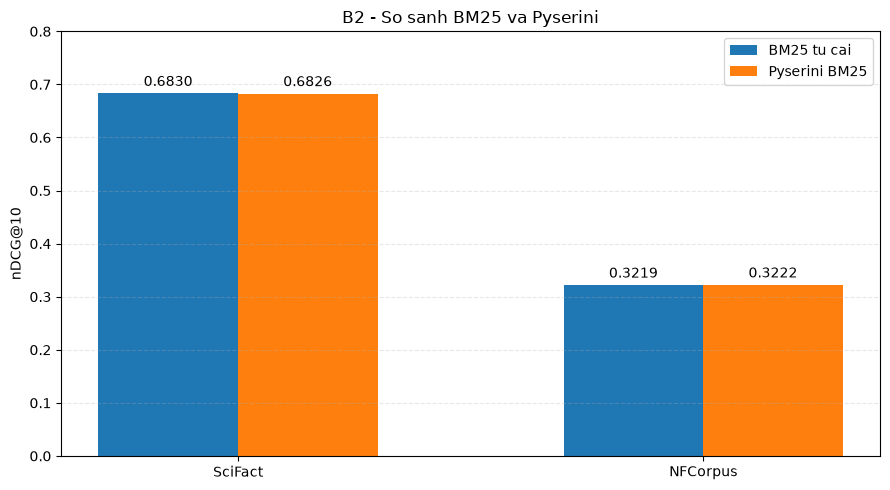

SciFact: |Δ| = 0.0004 - PASS
NFCorpus: |Δ| = 0.0003 - PASS


In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Kết quả thực nghiệm B2
datasets = ["SciFact", "NFCorpus"]

bm25_custom = [0.6830, 0.3219]
bm25_pyserini = [0.6826, 0.3222]

x = np.arange(len(datasets))
width = 0.3

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - width / 2,
    bm25_custom,
    width,
    label="BM25 tu cai"
)

bars2 = ax.bar(
    x + width / 2,
    bm25_pyserini,
    width,
    label="Pyserini BM25"
)

# Hiển thị giá trị trên từng cột
ax.bar_label(bars1, fmt="%.4f", padding=3)
ax.bar_label(bars2, fmt="%.4f", padding=3)

ax.set_title("B2 - So sanh BM25 va Pyserini")
ax.set_ylabel("nDCG@10")
ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.set_ylim(0, 0.8)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Kiểm tra yêu cầu B2
for dataset, custom, pyserini in zip(
    datasets, bm25_custom, bm25_pyserini
):
    diff = abs(custom - pyserini)
    print(f"{dataset}: |Δ| = {diff:.4f} - {'PASS' if diff < 0.01 else 'FAIL'}")